# Sindhudurg UHI — Python version (2010 – 2026)

Run the boxes **one at a time, top to bottom** (click a box → press **Shift + Enter**).
Each box has a short note above it explaining what it does.
The original Landsat files are only *read*, never changed. All results are saved to the `outputs` folder of this project.

**Expected results** (from the independent check) are given after some steps. If your numbers match, that step is correct.

## Step 0 — Check the setup
If this prints three version numbers, you're ready. If it shows `ModuleNotFoundError`, rasterio or geopandas isn't installed in the active environment yet.

In [1]:
import rasterio, geopandas, sklearn
print("rasterio", rasterio.__version__, "| geopandas", geopandas.__version__, "| scikit-learn", sklearn.__version__)

rasterio 1.4.3 | geopandas 1.1.3 | scikit-learn 1.6.1


## Step 1 — Settings
Where the data lives and where results go. **This is the only box you'd ever edit.**

In [2]:
import os, glob
import numpy as np

DATA     = r"G:\Sindhudurg_UHI_Analysis\Data"                       # original data (read only)
LANDSAT  = os.path.join(DATA, "Landsat")
BOUNDARY = os.path.join(DATA, "Sindhudurga", "Sindhudurga_District.shp")
DEM_DIR  = os.path.join(LANDSAT, "DEM")
OUT      = r"G:\Sindhudurg_UHI_Analysis_python\outputs"              # results of THIS project
os.makedirs(OUT, exist_ok=True)

# Which scene is used for each year (folder / file-name start)
SCENES = {
    2010: dict(folder=r"2010\Extracted", prefix="LE07_L2SP_147049_20100402", red="SR_B3", nir="SR_B4", swir="SR_B5", thermal="ST_B6"),
    2020: dict(folder=r"2020\Extracted", prefix="LC08_L2SP_147049_20200320", red="SR_B4", nir="SR_B5", swir="SR_B6", thermal="ST_B10"),
    2026: dict(folder=r"2026\LC09",      prefix="LC09_L2SP_147049_20260414", red="SR_B4", nir="SR_B5", swir="SR_B6", thermal="ST_B10"),
}
print("Output folder:", OUT)

Output folder: G:\Sindhudurg_UHI_Analysis_python\outputs


## Step 2 — Helper functions
Small reusable tools. Nothing is calculated yet, so just run it.

- `band_path` finds a band file.
- `read_on_grid` reads a band onto one common 30 m grid, so all years line up pixel by pixel.
- `clear_mask` uses the **QA_PIXEL** band to drop cloud, cloud shadow, cirrus, water and empty (fill) pixels.
- `save_tif` writes a result as a GeoTIFF you can drag into the map.
- `summary` prints mean / SD / 1st–99th percentile.

In [3]:
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.features import rasterize
from rasterio.transform import from_origin
import geopandas as gpd

# Landsat Collection-2 Level-2 scale factors (from the USGS product guide)
SR_SCALE, SR_OFFSET = 0.0000275, -0.2      # reflectance = DN * 0.0000275 - 0.2
ST_SCALE, ST_OFFSET = 0.00341802, 149.0    # temperature (K) = DN * 0.00341802 + 149

def band_path(year, band):
    s = SCENES[year]
    hits = glob.glob(os.path.join(LANDSAT, s["folder"], f'{s["prefix"]}*_{band}.TIF'))
    assert hits, f"Not found: {year} {band}"
    return hits[0]

def read_on_grid(path, resampling=Resampling.nearest):
    out = np.full(GRID["shape"], np.nan, dtype="float32")
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        reproject(arr, out, src_transform=src.transform, src_crs=src.crs,
                  dst_transform=GRID["transform"], dst_crs=GRID["crs"],
                  src_nodata=np.nan, dst_nodata=np.nan, resampling=resampling)
    return out

def clear_mask(qa_path):
    q = read_on_grid(qa_path)
    has_data = ~np.isnan(q)
    q = np.where(has_data, q, 1).astype(np.uint16)
    # QA_PIXEL bits: 0 fill, 1 dilated cloud, 2 cirrus, 3 cloud, 4 shadow, 7 water
    bad = np.zeros(q.shape, dtype=bool)
    for bit in (0, 1, 2, 3, 4, 7):
        bad |= ((q >> bit) & 1).astype(bool)
    return has_data & ~bad & INSIDE

def save_tif(arr, name):
    path = os.path.join(OUT, name + ".tif")
    with rasterio.open(path, "w", driver="GTiff", height=arr.shape[0], width=arr.shape[1], count=1,
                       dtype="float32", crs=GRID["crs"], transform=GRID["transform"],
                       nodata=np.nan, compress="deflate") as dst:
        dst.write(arr.astype("float32"), 1)
    print("saved", path)

def summary(name, arr, mask):
    v = arr[mask & np.isfinite(arr)]
    print(f"{name:14s} mean {v.mean():7.3f}  SD {v.std():6.3f}  p1 {np.percentile(v,1):7.2f}  p99 {np.percentile(v,99):7.2f}  pixels {v.size:,}")
    return float(v.mean()), float(v.std())

def ndi(a, b):   # normalised difference (a - b) / (a + b)
    with np.errstate(divide="ignore", invalid="ignore"):
        return (a - b) / (a + b)
print("helpers ready")

helpers ready


## Step 3 — District grid
Reproject the district boundary to UTM 43N and make one 30 m grid snapped to Landsat pixels. `INSIDE` is True for pixels inside the district.

*Expected:* district ≈ **5,105 km²** (the polygon. The official 5,207 km² figure includes areas not in this shapefile).

In [4]:
district = gpd.read_file(BOUNDARY).to_crs(32643)
print("District area (polygon):", round(district.area.sum() / 1e6, 1), "km2")

x0, y0, x1, y1 = district.total_bounds
x0 = np.floor((x0 - 15) / 30) * 30 + 15      # snap to the Landsat pixel grid
y1 = np.ceil((y1 - 15) / 30) * 30 + 15
w, h = int(np.ceil((x1 - x0) / 30)), int(np.ceil((y1 - y0) / 30))
GRID = dict(crs="EPSG:32643", transform=from_origin(x0, y1, 30, 30), shape=(h, w))
INSIDE = rasterize(district.geometry, out_shape=GRID["shape"], transform=GRID["transform"]) == 1
print("Grid:", GRID["shape"], "pixels inside district:", f"{INSIDE.sum():,}")

District area (polygon): 5105.2 km2
Grid: (3912, 3185) pixels inside district: 5,672,516


## Step 4 — LST, NDVI and NDBI for each year
For each year:
1. Read red, NIR and SWIR and **apply the scale factor** (the step that was missing before).
2. NDVI = (NIR − Red) / (NIR + Red), NDBI = (SWIR − NIR) / (SWIR + NIR).
3. LST = thermal DN × 0.00341802 + 149 − 273.15 (°C).
4. Keep only clear land pixels.

*Expected means (clear pixels):*

| Year | LST °C | NDVI | NDBI |
|---|---|---|---|
| 2010 | 41.45 | 0.442 | 0.025 |
| 2020 | 40.50 | 0.539 | −0.036 |
| 2026 | 43.05 | 0.541 | −0.051 |

2010 has only ~73 % clear pixels because of Landsat 7's stripe gaps (SLC-off). That's normal.

In [5]:
L = {}   # all results live in this dictionary, e.g. L["LST_2026"]

def process_year(year):
    s = SCENES[year]
    clear = clear_mask(band_path(year, "QA_PIXEL"))
    red  = read_on_grid(band_path(year, s["red"]))  * SR_SCALE + SR_OFFSET
    nir  = read_on_grid(band_path(year, s["nir"]))  * SR_SCALE + SR_OFFSET
    swir = read_on_grid(band_path(year, s["swir"])) * SR_SCALE + SR_OFFSET
    lst  = read_on_grid(band_path(year, s["thermal"])) * ST_SCALE + ST_OFFSET - 273.15
    ndvi, ndbi = ndi(nir, red), ndi(swir, nir)
    clear &= np.isfinite(lst) & np.isfinite(ndvi)
    for name, arr in (("LST", lst), ("NDVI", ndvi), ("NDBI", ndbi)):
        arr = np.where(clear, arr, np.nan)
        L[f"{name}_{year}"] = arr
        summary(f"{name}_{year}", arr, clear)
        save_tif(arr, f"{name}_{year}")
    L[f"clear_{year}"] = clear
    print(f"{year}: clear land = {100 * clear.sum() / INSIDE.sum():.1f} % of district\n")

for yr in (2010, 2020, 2026):
    process_year(yr)

LST_2010       mean  41.451  SD  5.031  p1   30.72  p99   51.78  pixels 4,126,308
saved G:\Sindhudurg_UHI_Analysis_python\outputs\LST_2010.tif
NDVI_2010      mean   0.442  SD  0.153  p1    0.15  p99    0.78  pixels 4,126,308
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDVI_2010.tif
NDBI_2010      mean   0.025  SD  0.159  p1   -0.37  p99    0.29  pixels 4,126,308
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDBI_2010.tif
2010: clear land = 72.7 % of district

LST_2020       mean  40.495  SD  5.135  p1   30.36  p99   52.77  pixels 5,527,447
saved G:\Sindhudurg_UHI_Analysis_python\outputs\LST_2020.tif
NDVI_2020      mean   0.539  SD  0.159  p1    0.22  p99    0.83  pixels 5,527,447
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDVI_2020.tif
NDBI_2020      mean  -0.036  SD  0.172  p1   -0.42  p99    0.27  pixels 5,527,447
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDBI_2020.tif
2020: clear land = 97.4 % of district

LST_2026       mean  43.049  SD  5.729  p1   32.20  p99   57

## Step 5 — Change detection (2010 → 2026)
Subtract the two years **only on pixels that are clear in both years**. Then take the mean of that difference map.
This is the correct warming figure. (Subtracting the two yearly means gives a different number, because 2010 has gaps.)

*Expected:* LST change ≈ **+2.08 °C**, NDVI change ≈ **+0.090**, NDBI change ≈ **−0.064**.

In [6]:
def change(var, y0, y1):
    both = L[f"clear_{y0}"] & L[f"clear_{y1}"]
    d = np.where(both, L[f"{var}_{y1}"] - L[f"{var}_{y0}"], np.nan)
    summary(f"{var} {y0}-{y1}", d, both)
    save_tif(d, f"{var}_Change_{y0}_{y1}")
    return d

for var in ("LST", "NDVI", "NDBI"):
    L[f"{var}_chg"] = change(var, 2010, 2026)

print("\nGreening split into two periods (look for the 2020 → 2026 plateau):")
_ = change("NDVI", 2010, 2020)
_ = change("NDVI", 2020, 2026)

LST 2010-2026  mean   2.076  SD  2.853  p1   -4.95  p99    9.54  pixels 4,120,325
saved G:\Sindhudurg_UHI_Analysis_python\outputs\LST_Change_2010_2026.tif
NDVI 2010-2026 mean   0.090  SD  0.077  p1   -0.13  p99    0.28  pixels 4,120,325
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDVI_Change_2010_2026.tif
NDBI 2010-2026 mean  -0.064  SD  0.084  p1   -0.28  p99    0.16  pixels 4,120,325
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDBI_Change_2010_2026.tif

Greening split into two periods (look for the 2020 → 2026 plateau):
NDVI 2010-2020 mean   0.087  SD  0.070  p1   -0.13  p99    0.26  pixels 4,113,960
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDVI_Change_2010_2020.tif
NDVI 2020-2026 mean   0.005  SD  0.066  p1   -0.18  p99    0.17  pixels 5,492,116
saved G:\Sindhudurg_UHI_Analysis_python\outputs\NDVI_Change_2020_2026.tif


## Step 6 — Seasonal check (optional, but strong for the report)
Is the warming just because 2026 was later in April? Compare two 2026 scenes **8 days apart**: Landsat 9 (14 Apr) vs Landsat 8 (22 Apr).
If the mean difference is near 0, the date gap barely matters.

*Expected:* ≈ **+0.08 °C**.

In [7]:
l8 = os.path.join(LANDSAT, r"2026\Extracted")
l8_lst = read_on_grid(glob.glob(os.path.join(l8, "LC08_L2SP_*_ST_B10.TIF"))[0]) * ST_SCALE + ST_OFFSET - 273.15
l8_clear = clear_mask(glob.glob(os.path.join(l8, "LC08_L2SP_*_QA_PIXEL.TIF"))[0])
both = l8_clear & L["clear_2026"]
_ = summary("22Apr - 14Apr", l8_lst - L["LST_2026"], both)

22Apr - 14Apr  mean   0.082  SD  3.250  p1   -9.82  p99    4.89  pixels 5,441,663


## Step 7 — Elevation (SRTM)
Merge the four SRTM tiles and put them on the same grid. Used as the third predictor.

In [10]:
from rasterio.merge import merge
from pyproj import Transformer

dem_files = sorted(glob.glob(os.path.join(DEM_DIR, "*.tif")))
print("DEM tiles found:", [os.path.basename(p) for p in dem_files])
mosaic, mtr = merge([rasterio.open(p) for p in dem_files])
src = mosaic[0].astype("float32")
src[src == -32767] = np.nan                     # SRTM "no data" value
print("SRTM elevation range:", np.nanmin(src), "to", np.nanmax(src), "m")

# For every district pixel: UTM centre -> lon/lat (pyproj) -> nearest SRTM cell
rows, cols = np.nonzero(INSIDE)
t = GRID["transform"]
x = t.c + (cols + 0.5) * t.a
y = t.f + (rows + 0.5) * t.e
lon, lat = Transformer.from_crs(32643, 4326, always_xy=True).transform(x, y)
r = ((lat - mtr.f) / mtr.e).astype(int)
c = ((lon - mtr.c) / mtr.a).astype(int)

DEM = np.full(GRID["shape"], np.nan, "float32")
DEM[rows, cols] = src[r, c]
print("DEM pixels with data:", f"{np.isfinite(DEM).sum():,}")
_ = summary("DEM (m)", DEM, INSIDE)
save_tif(DEM, "DEM")

DEM tiles found: ['n15_e073_1arc_v3 (2).tif', 'n15_e074_1arc_v3.tif', 'n16_e073_1arc_v3.tif', 'n16_e074_1arc_v3.tif']
SRTM elevation range: -42.0 to 1050.0 m
DEM pixels with data: 5,672,516
DEM (m)        mean 146.479  SD 167.293  p1    2.00  p99  835.00  pixels 5,672,516
saved G:\Sindhudurg_UHI_Analysis_python\outputs\DEM.tif


## Step 8 — Random Forest: what controls LST in 2026?
- Take 30,000 random clear pixels, using NDVI, NDBI and DEM to predict LST.
- **Hold out 25 % for testing using 5 km blocks.** Neighbouring pixels are nearly identical, so a random split would "test" on near-copies of the training data and look better than it really is.
- Report **test** R² and RMSE, plus two kinds of importance.

*Expected:* test R² ≈ **0.72**, RMSE ≈ **3.0 °C**, NDBI most important (~68 %). NDVI and NDBI correlate at about **r = −0.92**, which belongs in your limitations.

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error

ok = L["clear_2026"] & np.isfinite(DEM)
rows, cols = np.nonzero(ok)
rng = np.random.default_rng(42)
pick = rng.choice(rows.size, size=30000, replace=False)
r, c = rows[pick], cols[pick]
X = np.column_stack([L["NDVI_2026"][r, c], L["NDBI_2026"][r, c], DEM[r, c]])
y = L["LST_2026"][r, c]

block = (r // 167) * 1000 + (c // 167)                  # 167 px x 30 m = 5 km blocks
test_blocks = rng.choice(np.unique(block), size=len(np.unique(block)) // 4, replace=False)
test = np.isin(block, test_blocks); train = ~test

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X[train], y[train])
pred = rf.predict(X[test])
print(f"train n = {train.sum():,}   test n = {test.sum():,}")
print(f"TEST  R2 = {r2_score(y[test], pred):.3f}   RMSE = {np.sqrt(mean_squared_error(y[test], pred)):.2f} °C")
print(f"train R2 = {r2_score(y[train], rf.predict(X[train])):.3f}  (always higher, don't report this one)")

names = ["NDVI", "NDBI", "DEM"]
pi = permutation_importance(rf, X[test], y[test], n_repeats=5, random_state=42, n_jobs=1)
for n, imp, p in zip(names, rf.feature_importances_, pi.importances_mean):

    print(f"{n:5s} importance {100*imp:5.1f} %   permutation (test) {p:.3f}")
print("corr(NDVI, NDBI) =", round(np.corrcoef(X[:, 0], X[:, 1])[0, 1], 3))

train n = 22,658   test n = 7,342
TEST  R2 = 0.720   RMSE = 2.99 °C
train R2 = 0.852  (always higher, don't report this one)
NDVI  importance  19.9 %   permutation (test) 0.312
NDBI  importance  68.6 %   permutation (test) 0.689
DEM   importance  11.5 %   permutation (test) 0.141
corr(NDVI, NDBI) = -0.922


## Step 9 — Predicted LST and residual maps
Apply the model to every clear pixel. Residual = observed − predicted.

In [14]:
rr, cc = np.nonzero(ok)
pred_map = np.full(GRID["shape"], np.nan, "float32")
pred_map[rr, cc] = rf.predict(np.column_stack([L["NDVI_2026"][rr, cc], L["NDBI_2026"][rr, cc], DEM[rr, cc]]))
save_tif(pred_map, "LST_Predicted_RF_2026")
save_tif(L["LST_2026"] - pred_map, "Residual_RF_2026")

saved G:\Sindhudurg_UHI_Analysis_python\outputs\LST_Predicted_RF_2026.tif
saved G:\Sindhudurg_UHI_Analysis_python\outputs\Residual_RF_2026.tif


## Step 10 — Thermal hotspots 2026
Hotspot = LST above **mean + 1 SD** of clear land pixels.

*Expected:* threshold ≈ **48.78 °C**, area ≈ **826 km²** (~16.6 % of clear land).

In [15]:
m, sd = summary("LST_2026", L["LST_2026"], L["clear_2026"])
thr = m + sd
hot = L["clear_2026"] & (L["LST_2026"] > thr)
km2 = hot.sum() * 900 / 1e6
print(f"threshold {thr:.2f} °C | hotspot area {km2:.1f} km2 | {100*hot.sum()/L['clear_2026'].sum():.1f} % of clear land")
save_tif(np.where(INSIDE, hot.astype("float32"), np.nan), "Hotspots_2026")

LST_2026       mean  43.049  SD  5.729  p1   32.20  p99   57.06  pixels 5,517,009
threshold 48.78 °C | hotspot area 826.4 km2 | 16.6 % of clear land
saved G:\Sindhudurg_UHI_Analysis_python\outputs\Hotspots_2026.tif


## Step 11 — Add the results to your map
Adds every GeoTIFF from `outputs` to the current map. Then style them as usual (Symbology pane).

*(ArcGIS Pro only. Skip this step outside Pro.)*

In [16]:
import arcpy
aprx = arcpy.mp.ArcGISProject("CURRENT")
mp = aprx.activeMap or aprx.listMaps()[0]
for tif in sorted(glob.glob(os.path.join(OUT, "*.tif"))):
    mp.addDataFromPath(tif)
    print("added", os.path.basename(tif))

added DEM.tif
added Hotspots_2026.tif
added LST_2010.tif
added LST_2020.tif
added LST_2026.tif
added LST_Change_2010_2026.tif
added LST_Predicted_RF_2026.tif
added NDBI_2010.tif
added NDBI_2020.tif
added NDBI_2026.tif
added NDBI_Change_2010_2026.tif
added NDVI_2010.tif
added NDVI_2020.tif
added NDVI_2026.tif
added NDVI_Change_2010_2020.tif
added NDVI_Change_2010_2026.tif
added NDVI_Change_2020_2026.tif
added Residual_RF_2026.tif


## Step 12 — Finished maps (PNG, 300 dpi)
Shared colour scales across years, district outline, north arrow, scale bar. Saved to `outputs/maps`.

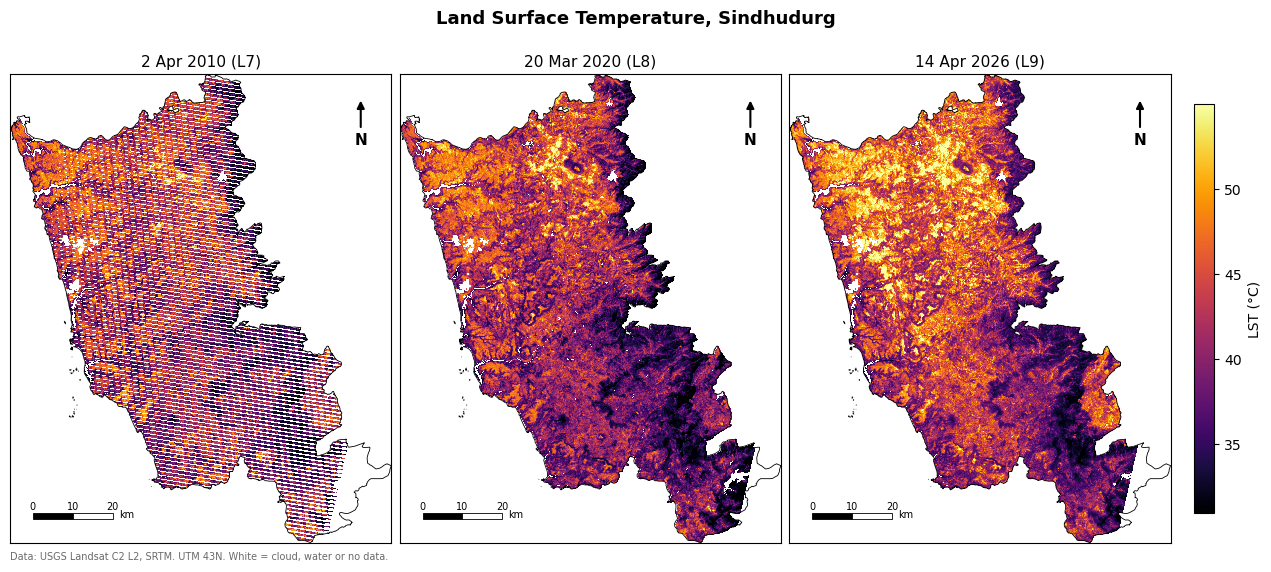

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\01_LST_by_year.png


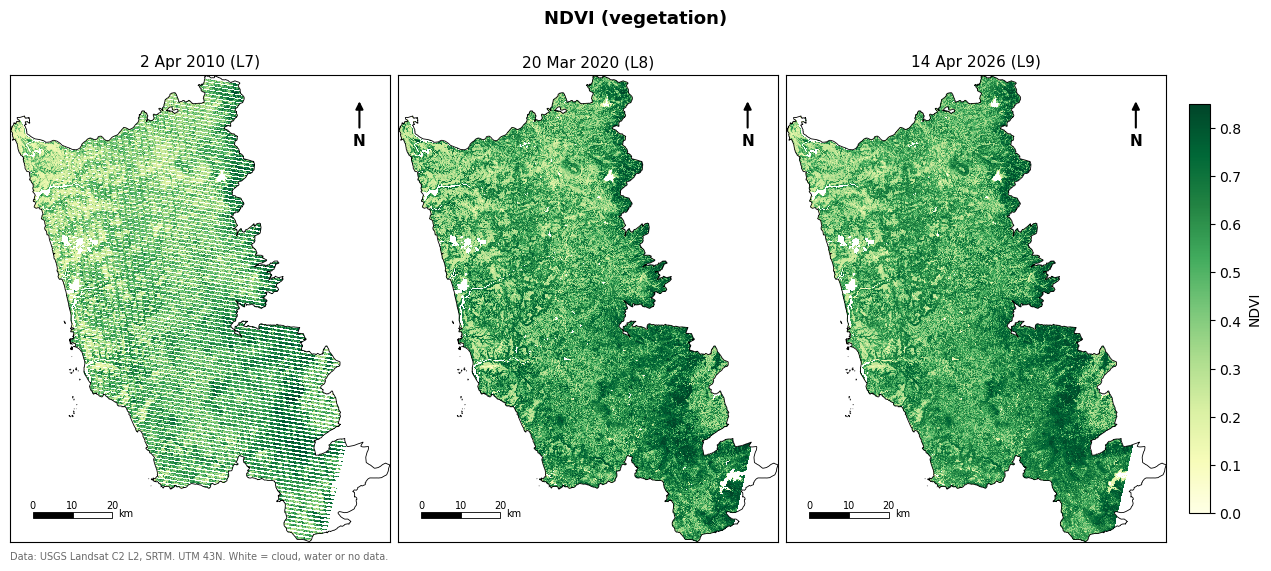

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\02_NDVI_by_year.png


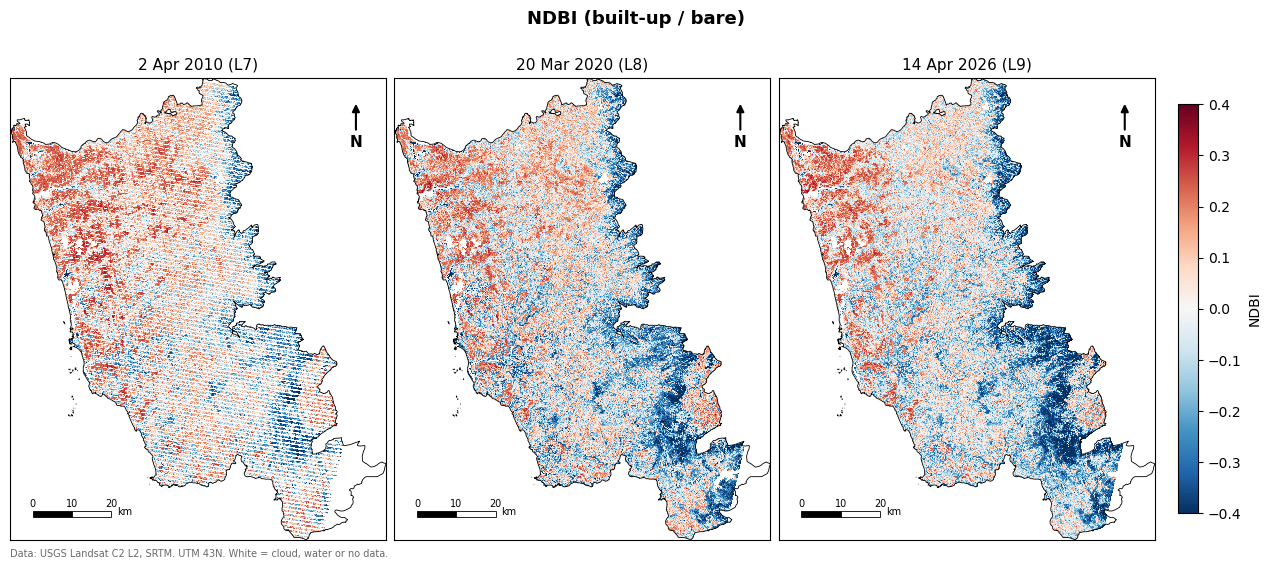

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\03_NDBI_by_year.png


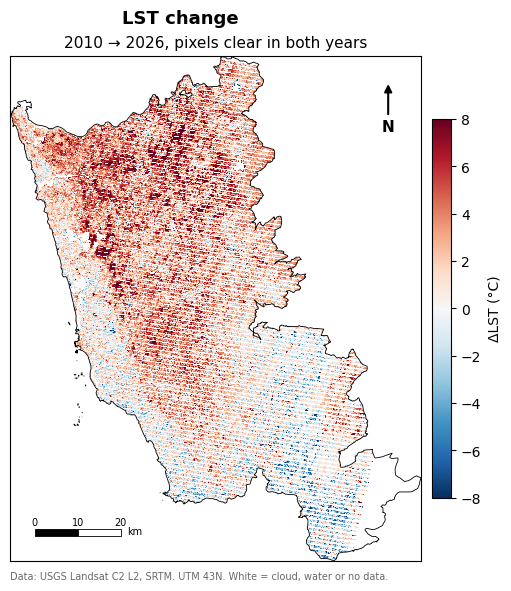

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\04_LST_change_2010_2026.png


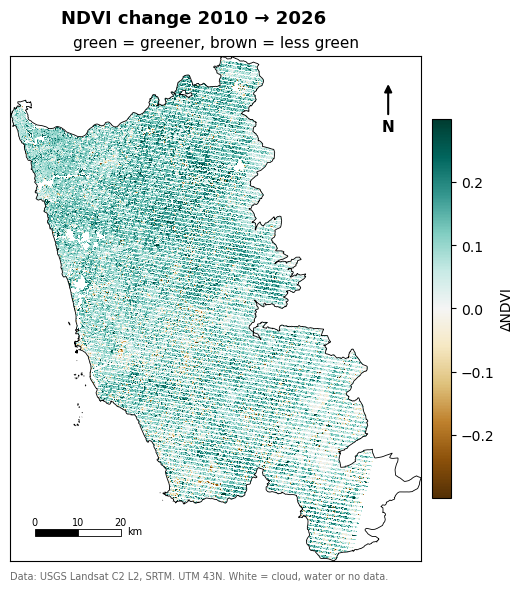

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\05_NDVI_change_2010_2026.png


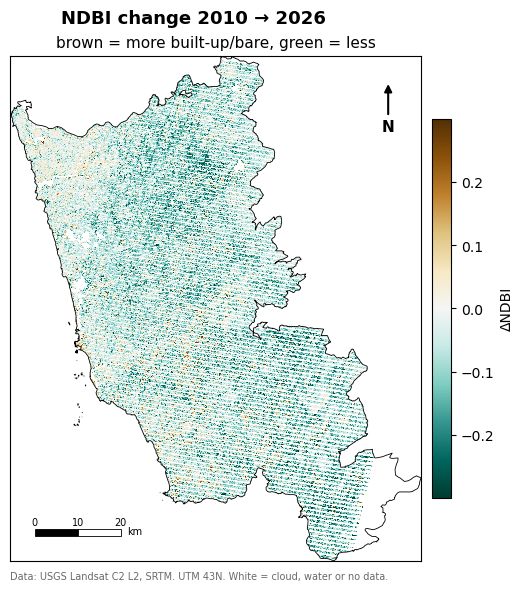

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\06_NDBI_change_2010_2026.png


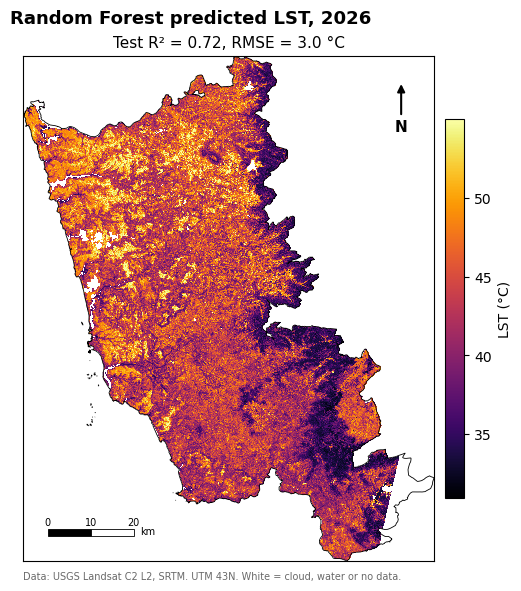

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\07_RF_predicted_LST_2026.png


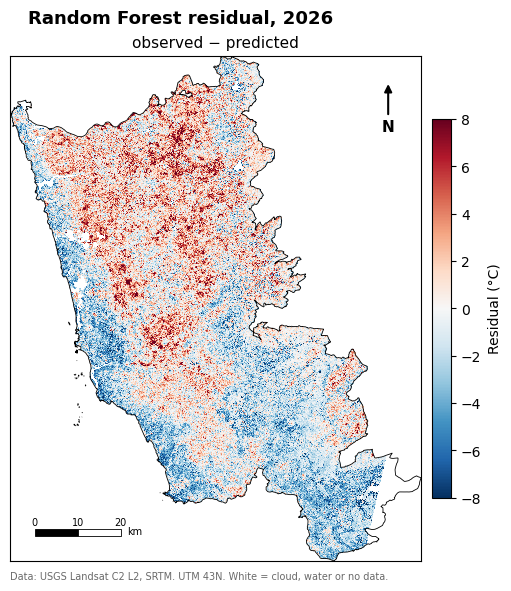

saved G:\Sindhudurg_UHI_Analysis_python\outputs\maps\08_RF_residual_2026.png


In [17]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, ListedColormap

MAPS = os.path.join(OUT, "maps")
os.makedirs(MAPS, exist_ok=True)
t = GRID["transform"]
EXTENT = (t.c, t.c + t.a * GRID["shape"][1], t.f + t.e * GRID["shape"][0], t.f)   # left, right, bottom, top

def decorate(ax):
    """District outline, north arrow, 20 km scale bar, no axis ticks."""
    district.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    ax.annotate("N", xy=(0.92, 0.95), xytext=(0.92, 0.85), xycoords="axes fraction",
                ha="center", fontsize=11, fontweight="bold",
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.5))
    x0 = EXTENT[0] + 0.06 * (EXTENT[1] - EXTENT[0]); y0 = EXTENT[2] + 0.05 * (EXTENT[3] - EXTENT[2])
    for i, col in enumerate(("black", "white")):
        ax.add_patch(plt.Rectangle((x0 + i * 10000, y0), 10000, 1500, facecolor=col, edgecolor="black", lw=0.6))
    for km in (0, 10, 20):
        ax.text(x0 + km * 1000, y0 + 2500, str(km), ha="center", fontsize=7)
    ax.text(x0 + 21500, y0 + 400, "km", fontsize=7)

def make_map(arrays, titles, fname, suptitle, cmap, label, vmin=None, vmax=None, diverging=False, legend=None):
    n = len(arrays)
    fig, axes = plt.subplots(1, n, figsize=(max(4.2 * n, 6.5), 5.8), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for ax, arr, ttl in zip(axes, arrays, titles):
        norm = TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax) if diverging else None
        im = ax.imshow(arr, extent=EXTENT, cmap=cmap, norm=norm,
                       vmin=None if diverging else vmin, vmax=None if diverging else vmax,
                       interpolation="nearest")
        ax.set_title(ttl, fontsize=11)
        decorate(ax)
    if legend:      # categorical map: legend boxes instead of a colour bar
        from matplotlib.patches import Patch
        axes[-1].legend(handles=[Patch(facecolor=c, edgecolor="black", label=l) for l, c in legend],
                        loc="lower right", fontsize=8, frameon=True)
    else:
        cb = fig.colorbar(im, ax=axes, shrink=0.75, pad=0.02)
        cb.set_label(label)
    fig.suptitle(suptitle, fontsize=13, fontweight="bold")
    axes[0].text(0, -0.02, "Data: USGS Landsat C2 L2, SRTM. UTM 43N. White = cloud, water or no data.",
                 transform=axes[0].transAxes, va="top", fontsize=7, color="dimgray")
    path = os.path.join(MAPS, fname)
    fig.savefig(path, dpi=300, facecolor="white")
    plt.show()
    print("saved", path)

YEARS = (2010, 2020, 2026)
DATES = {2010: "2 Apr 2010 (L7)", 2020: "20 Mar 2020 (L8)", 2026: "14 Apr 2026 (L9)"}

# 1. LST for each year — one shared colour scale (1st–99th percentile across years)
lo, hi = np.nanpercentile(np.concatenate([L[f"LST_{y}"][L[f"clear_{y}"]] for y in YEARS]), [1, 99])
make_map([L[f"LST_{y}"] for y in YEARS], [DATES[y] for y in YEARS], "01_LST_by_year.png",
         "Land Surface Temperature, Sindhudurg", "inferno", "LST (°C)", lo, hi)

# 2. NDVI and 3. NDBI for each year — fixed shared scales so years are comparable
make_map([L[f"NDVI_{y}"] for y in YEARS], [DATES[y] for y in YEARS], "02_NDVI_by_year.png",
         "NDVI (vegetation)", "YlGn", "NDVI", 0.0, 0.85)
make_map([L[f"NDBI_{y}"] for y in YEARS], [DATES[y] for y in YEARS], "03_NDBI_by_year.png",
         "NDBI (built-up / bare)", "RdBu_r", "NDBI", -0.4, 0.4, diverging=True)

# 4. Change 2010 -> 2026 (diverging, centred on 0)
make_map([L["LST_chg"]], ["2010 → 2026, pixels clear in both years"], "04_LST_change_2010_2026.png",
         "LST change", "RdBu_r", "ΔLST (°C)", -8, 8, diverging=True)
make_map([L["NDVI_chg"]], ["green = greener, brown = less green"], "05_NDVI_change_2010_2026.png",
         "NDVI change 2010 → 2026", "BrBG", "ΔNDVI", -0.3, 0.3, diverging=True)
make_map([L["NDBI_chg"]], ["brown = more built-up/bare, green = less"], "06_NDBI_change_2010_2026.png",
         "NDBI change 2010 → 2026", "BrBG_r", "ΔNDBI", -0.3, 0.3, diverging=True)

# 5. Random Forest: predicted LST and residual
make_map([pred_map], [f"Test R² = {r2_score(y[test], pred):.2f}, RMSE = {np.sqrt(mean_squared_error(y[test], pred)):.1f} °C"],
         "07_RF_predicted_LST_2026.png", "Random Forest predicted LST, 2026", "inferno", "LST (°C)", lo, hi)
make_map([L["LST_2026"] - pred_map], ["observed − predicted"], "08_RF_residual_2026.png",
         "Random Forest residual, 2026", "RdBu_r", "Residual (°C)", -8, 8, diverging=True)

# 6. Hotspots
hot_map = np.where(L["clear_2026"], hot.astype(float), np.nan)
make_map([hot_map], [f"LST > {thr:.1f} °C (mean + 1 SD): {km2:.0f} km²"], "09_Hotspots_2026.png",
         "Thermal hotspots, 2026", ListedColormap(["#e8e8e8", "#d7301f"]), "", 0, 1,
         legend=[("Hotspot", "#d7301f"), ("Not hotspot", "#e8e8e8")])
